# Notebook 11 — Instituições de referência e fatores do Regime de Trabalho (Civil, Produção e Arquitetura)

Este notebook aprofunda os três cursos escolhidos depois do agrupamento das 8 áreas (notebook 09):
**Engenharia Civil**, **Engenharia de Produção** e **Arquitetura e Urbanismo**.

Ponto de partida: no cenário principal C2 (8 indicadores, K=4), o Regime de Trabalho é o indicador em que a PUC-Rio
mais se afasta dos pares nos três cursos. As perguntas aqui são:

1. Como a PUC-Rio se compara aos pares privados no curso (CPC) e na instituição (Censo da Educação Superior 2023)?
2. Quais instituições privadas do mesmo grupo são as melhores referências? (**k-NN**)
3. Quanto da diferença de Regime entre cursos vem da instituição? (**decomposição de variância**)
4. O Regime de cada curso da PUC-Rio está onde o perfil da instituição prevê? (**Random Forest**)
5. Com quem a PUC-Rio se parece em vários níveis de proximidade? (**agrupamento hierárquico**, Cabezas, Izbicki e Stern, 2023)

Tudo é registrado no MLflow, no experimento `CPC2023_referencias_e_regime_3cursos`.

In [1]:
# Célula 1 — Configuração: 3 cursos do foco, arquivos e experimento do MLflow
import os, time, warnings
os.environ["GIT_PYTHON_REFRESH"] = "quiet"; os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy.cluster.hierarchy import linkage, cophenet, fcluster, to_tree, dendrogram
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import adjusted_rand_score, mean_absolute_error, pairwise_distances, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import mlflow

FOCO = {5710: "Engenharia Civil", 6208: "Engenharia de Produção", 21: "Arquitetura e Urbanismo"}
AREAS_8 = [5710, 6208, 21, 5902, 5806, 6307, 6008, 5814]
NOME_AREA = {5710: "Civil", 6208: "Produção", 21: "Arquitetura", 5902: "Mecânica", 5806: "Elétrica",
             6307: "Ambiental", 6008: "Química", 5814: "Controle e Automação"}
IND = ["Enade_2023", "IDD_2023", "Mestres_2023", "Doutores_2023", "Regime_Trabalho_2023",
       "Organizacao_Didatica_2023", "Infraestrutura_2023", "Oportunidades_2023"]
NOMES = ["ENADE", "IDD", "Mestres", "Doutores", "Regime", "Org. didática", "Infraestrutura", "Oportunidades"]
CODIGO_IES_PUC, SEMENTE = 528, 42
EXPERIMENTO_MLFLOW = "CPC2023_referencias_e_regime_3cursos"

pasta_saida = Path("resultados_notebook_11"); pasta_saida.mkdir(exist_ok=True)
AZUL, AZUL_ESC, LARANJA, CINZA, TXT, GRADE = "#2a78d6", "#002060", "#eb6834", "#c9c7c1", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRADE,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "legend.frameon": False,
                     "xtick.color": TXT, "ytick.color": TXT, "axes.labelcolor": TXT,
                     "axes.titleweight": "bold", "axes.titlecolor": AZUL_ESC})
print("Cursos do foco:", list(FOCO.values()))

Cursos do foco: ['Engenharia Civil', 'Engenharia de Produção', 'Arquitetura e Urbanismo']


## Dados

- **CPC 2023 (INEP):** cursos presenciais das 8 áreas, com a nota bruta de Regime (proporção de docentes do curso em tempo integral ou parcial).
- **Censo da Educação Superior 2023, arquivo de IES:** perfil dos docentes de cada instituição (integral, parcial, horista, titulação, idade).
  Os microdados públicos não trazem os docentes por curso, só por instituição.
- **Grupos do C2:** modelo final do notebook 09 (treino de 80%, semente 42), refeito aqui para os três cursos.

In [2]:
# Célula 2 — Dados: CPC 2023 (INEP), base analítica, Censo IES 2023 e grupos do C2 (modelo final do notebook 09)

cpc = pd.read_excel("dados/CPC_2023.xlsx", "CPC_2023"); cpc.columns = cpc.columns.str.strip()
cpc = cpc[cpc["Código da Área"].isin(AREAS_8) & cpc["Modalidade de Ensino"].eq("Educação Presencial")]
cpc = cpc.rename(columns={"Nota Bruta – Regime de Trabalho": "pct_nao_horista_curso"})
cpc["pct_nao_horista_curso"] *= 100
cpc["Privada"] = ~cpc["Categoria Administrativa"].str.startswith("Pública")

ies = pd.read_csv("dados/MICRODADOS_ED_SUP_IES_2023.CSV", sep=";", encoding="latin1", low_memory=False)
ies = ies[ies["QT_DOC_EXE"] > 0].copy(); n_doc = ies["QT_DOC_EXE"]
ies = ies.assign(**{
    "IES % integral": 100 * ies["QT_DOC_EX_INT"] / n_doc, "IES % dedicação exclusiva": 100 * ies["QT_DOC_EX_INT_DE"] / n_doc,
    "IES % parcial": 100 * ies["QT_DOC_EX_PARC"] / n_doc, "IES % horista": 100 * ies["QT_DOC_EX_HOR"] / n_doc,
    "IES % não horista": 100 * (ies["QT_DOC_EX_INT"] + ies["QT_DOC_EX_PARC"]) / n_doc,
    "IES % doutores": 100 * ies["QT_DOC_EX_DOUT"] / n_doc, "IES % mestres": 100 * ies["QT_DOC_EX_MEST"] / n_doc,
    "IES % 60+ anos": 100 * ies["QT_DOC_EX_60_MAIS"] / n_doc, "IES docentes": n_doc, "IES docentes (log)": np.log10(n_doc),
    "IES técnicos por docente": ies["QT_TEC_TOTAL"] / n_doc, "Universidade": ies["TP_ORGANIZACAO_ACADEMICA"].eq(1).astype(int),
    "Comunitária": ies["IN_COMUNITARIA"].fillna(0).astype(int), "Sem fins lucrativos": ies["TP_CATEGORIA_ADMINISTRATIVA"].eq(5).astype(int),
    "Capital": ies["IN_CAPITAL_IES"].fillna(0).astype(int)})
COLS_IES = ["IES % integral", "IES % dedicação exclusiva", "IES % parcial", "IES % horista", "IES % não horista",
            "IES % doutores", "IES % mestres", "IES % 60+ anos", "IES docentes", "IES docentes (log)",
            "IES técnicos por docente", "Universidade", "Comunitária", "Sem fins lucrativos", "Capital"]
cursos = cpc.merge(ies.set_index("CO_IES")[["SG_IES"] + COLS_IES], left_on="Código da IES", right_index=True, how="inner")
COLS_AREA = [f"Área: {NOME_AREA[a]}" for a in AREAS_8]   # indicadoras da área do curso (para o Random Forest)
for a, col in zip(AREAS_8, COLS_AREA):
    cursos[col] = cursos["Código da Área"].eq(a).astype(int)

base = pd.read_csv("dados/processados/base_analitica_1907_cursos.csv", encoding="utf-8-sig")
base.columns = base.columns.str.replace(chr(0xFEFF), "", regex=False).str.strip()
base = base.merge(cpc[["Código do Curso", "Sigla da IES", "Categoria Administrativa"]], on="Código do Curso", how="left")
base["Pública"] = base["Categoria Administrativa"].str.startswith("Pública")
k_c2 = pd.read_csv("resultados_notebook_09/k_escolhido_por_area.csv", sep=";", decimal=",") \
         .query("Cenario == 'C2_8IND'").set_index("Area")["K_escolhido"]

grupos_c2 = {}
for a in FOCO:
    d = base[base["Area_2023"] == a].reset_index(drop=True)
    tr, _ = train_test_split(np.arange(len(d)), test_size=0.2, random_state=SEMENTE)
    m = Pipeline([("e", StandardScaler()), ("k", KMeans(n_clusters=int(k_c2[a]), random_state=SEMENTE, n_init=20))]).fit(d.loc[tr, IND])
    g = m.predict(d[IND]); pos = int(np.flatnonzero(d["Código da IES"].eq(CODIGO_IES_PUC))[0])
    grupos_c2[a] = {"dados": d, "grupos": g, "pos": pos,
                    "pares": set(d.loc[(g == g[pos]) & (np.arange(len(d)) != pos), "Código do Curso"])}
cursos["Par C2 da PUC"] = [c in grupos_c2.get(a, {"pares": set()})["pares"] for c, a in zip(cursos["Código do Curso"], cursos["Código da Área"])]
eh_puc = cursos["Código da IES"].eq(CODIGO_IES_PUC)

print("Cursos CPC 2023 (8 áreas, presenciais, com Censo):", len(cursos))
display(ies.loc[ies["CO_IES"] == CODIGO_IES_PUC, ["SG_IES", "IES docentes", "IES % integral", "IES % parcial", "IES % horista", "IES % doutores"]].round(1))

Cursos CPC 2023 (8 áreas, presenciais, com Censo): 3424


,SG_IES,IES docentes,IES % integral,IES % parcial,IES % horista,IES % doutores
239,PUC-RIO,1216,37.7,8.6,53.7,71.0


## PUC-Rio × pares privados do grupo

Compara o percentual de docentes não horistas do curso (CPC) e o perfil dos docentes da instituição (Censo).
Os pares são as instituições privadas do mesmo grupo C2 da PUC-Rio (mediana).

In [3]:
# Célula 3 — PUC-Rio × pares privados do grupo C2: curso (CPC) e instituição (Censo)

COMP = ["pct_nao_horista_curso", "IES % não horista", "IES % integral", "IES % parcial", "IES % horista", "IES % doutores", "IES docentes"]
perfil = []
for a, nome in FOCO.items():
    na = cursos["Código da Área"].eq(a)
    p = cursos[na & eh_puc][COMP].iloc[0]
    pares = cursos[na & cursos["Par C2 da PUC"] & cursos["Privada"] & ~eh_puc]
    perfil.append({"Curso": nome, "Quem": "PUC-Rio", "N": 1, **p.to_dict()})
    perfil.append({"Curso": nome, "Quem": "Pares privados (mediana)", "N": len(pares), **pares[COMP].median().to_dict()})
perfil = pd.DataFrame(perfil).rename(columns={"pct_nao_horista_curso": "Curso % não horista"})
display(perfil.round(1))

,Curso,Quem,N,Curso % não horista,IES % não horista,IES % integral,IES % parcial,IES % horista,IES % doutores,IES docentes
0,Engenharia Civil,PUC-Rio,1,62.0,46.3,37.7,8.6,53.7,71.0,1216.0
1,Engenharia Civil,Pares privados (mediana),6,94.7,77.5,32.8,46.4,22.5,44.5,388.5
2,Engenharia de Produção,PUC-Rio,1,51.8,46.3,37.7,8.6,53.7,71.0,1216.0
3,Engenharia de Produção,Pares privados (mediana),79,88.9,71.6,32.7,40.7,28.4,35.9,334.0
4,Arquitetura e Urbanismo,PUC-Rio,1,29.4,46.3,37.7,8.6,53.7,71.0,1216.0
5,Arquitetura e Urbanismo,Pares privados (mediana),44,68.5,60.7,23.9,31.4,39.3,26.9,221.0


## Protocolo dos modelos supervisionados (k-NN e Random Forest)

Segue a aula de classificação (treino, validação e teste) e o mesmo desenho de divisões do K-means:

- **Teste externo:** 20% das instituições privadas são separadas antes de tudo. Cursos da mesma IES nunca ficam
  no treino e no teste ao mesmo tempo, para o modelo não "decorar" a instituição.
- **Validação:** no treino, validação cruzada de 5 partes, também agrupada por IES, escolhe os parâmetros
  (menor erro médio de validação).
- **Teste:** o modelo escolhido é treinado no treino inteiro e medido uma única vez no teste. É o valor reportado.
- **Repetição:** 10 divisões (sementes 42 a 51) e 40%, 70% e 100% das IES do treino.
- **Referência mínima:** prever a média do treino. O modelo só serve se errar menos que isso.

Alvo: % de docentes não horistas do curso (nota bruta do Regime). A PUC-Rio nunca entra no treino.

In [4]:
# Célula 4 — Protocolo dos modelos supervisionados (k-NN e Random Forest), como na aula de classificação:
#   teste externo: 20% das IES privadas separadas antes de tudo (cursos da mesma IES nunca ficam dos dois lados);
#   treino: validação cruzada de 5 partes agrupada por IES escolhe os parâmetros (menor erro médio de validação);
#   o modelo escolhido é treinado no treino inteiro e avaliado uma única vez no teste;
#   10 divisões (sementes 42 a 51) e 40%, 70% e 100% das IES do treino, como no K-means.
# Alvo: % de docentes não horistas do curso (nota bruta do Regime). Referência mínima: prever a média do treino.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import KNeighborsRegressor

SEMENTES, PROPORCOES, ALVO = list(range(42, 52)), [0.4, 0.7, 1.0], "pct_nao_horista_curso"
ATRIB_KNN = ["IES % doutores", "IES % mestres", "IES % 60+ anos", "IES docentes (log)", "Universidade",
             "Comunitária", "Sem fins lucrativos", "Conceito Enade (Contínuo)", "Nota Padronizada - IDD"]
ATRIB_RF = ["IES % integral", "IES % dedicação exclusiva", "IES % parcial", "IES % doutores", "IES % mestres",
            "IES % 60+ anos", "IES docentes (log)", "IES técnicos por docente", "Universidade", "Comunitária",
            "Sem fins lucrativos", "Capital"] + COLS_AREA
sup =cursos[cursos["Privada"] & ~eh_puc].dropna(subset=sorted(set(ATRIB_KNN + ATRIB_RF)) + [ALVO]).reset_index(drop=True)
DIVISOES = {sem: next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=sem).split(sup, groups=sup["Código da IES"]))
            for sem in SEMENTES}

def avaliar(nome_modelo, fabrica, grade, cols):
    """Valida, escolhe os parâmetros no treino e mede no teste, em cada divisão e tamanho de treino."""
    linhas, modelos = [], {}
    for sem, (tr, te) in DIVISOES.items():
        g_tr, y_tr, y_te = sup.loc[tr, "Código da IES"].to_numpy(), sup.loc[tr, ALVO], sup.loc[te, ALVO]
        val = []
        for par in grade:
            p = cross_val_predict(fabrica(par), sup.loc[tr, cols], y_tr, groups=g_tr, cv=GroupKFold(n_splits=5))
            val.append((mean_absolute_error(y_tr, p), r2_score(y_tr, p), par))
        mae_val, r2_val, melhor = min(val, key=lambda t: t[0])
        ies_tr = np.random.default_rng(sem).permutation(np.unique(g_tr))
        for prop in PROPORCOES:
            sub = tr[np.isin(g_tr, ies_tr[:int(round(prop * len(ies_tr)))])]
            m = fabrica(melhor).fit(sup.loc[sub, cols], sup.loc[sub, ALVO])
            p_sub, p_te = m.predict(sup.loc[sub, cols]), m.predict(sup.loc[te, cols])
            lin = {"Modelo": nome_modelo, "Semente": sem, "Proporção": prop, "Parâmetros": str(melhor),
                   "N treino": len(sub), "IES treino": int(sup.loc[sub, "Código da IES"].nunique()), "N teste": len(te),
                   "R² treino": r2_score(sup.loc[sub, ALVO], p_sub), "MAE treino": mean_absolute_error(sup.loc[sub, ALVO], p_sub),
                   "R² teste": r2_score(y_te, p_te), "MAE teste": mean_absolute_error(y_te, p_te),
                   "MAE teste (média do treino)": mean_absolute_error(y_te, np.full(len(te), sup.loc[sub, ALVO].mean()))}
            if prop == 1.0:
                lin.update({"R² validação": r2_val, "MAE validação": mae_val}); modelos[sem] = m
            linhas.append(lin)
    return pd.DataFrame(linhas), modelos

def resumir(log):
    t = (log.groupby(["Modelo", "Proporção"], sort=False)
            .agg(**{"N treino": ("N treino", "mean"), "IES treino": ("IES treino", "mean"), "N teste": ("N teste", "mean"),
                    **{f"{c}": (c, "mean") for c in ["R² treino", "R² validação", "R² teste", "MAE treino", "MAE validação",
                                                     "MAE teste", "MAE teste (média do treino)"]},
                    "R² teste (desvio)": ("R² teste", "std"), "R² teste (mín.)": ("R² teste", "min"),
                    "Parâmetros mais escolhidos": ("Parâmetros", lambda s: s.mode().iloc[0])}).reset_index())
    t["Ganho sobre a média (p.p.)"] = t["MAE teste (média do treino)"] - t["MAE teste"]
    t["Treino − teste (R²)"] = t["R² treino"] - t["R² teste"]
    return t

print(f"Base supervisionada: {len(sup)} cursos privados de {sup['Código da IES'].nunique()} IES (PUC-Rio fora)")
print("Teste externo por divisão:", sorted({len(te) for _, te in DIVISOES.values()}), "cursos")

Base supervisionada: 2283 cursos privados de 672 IES (PUC-Rio fora)
Teste externo por divisão: [379, 393, 407, 429, 438, 440, 443, 447, 468, 497] cursos


## k-NN: qualidade e instituições de referência

**Qualidade.** O k-NN prevê o % de não horistas do curso a partir do perfil da instituição sem o Regime
(titulação, idade e porte do corpo docente, tipo de instituição, ENADE e IDD). A validação escolhe k e a distância
(euclidiana ou Manhattan).

**Referências.** Dentro do grupo C2 da PUC-Rio, entre as privadas, as 5 **instituições distintas** mais parecidas
com a PUC-Rio, com a distância escolhida na validação. **O Regime fica de fora**, para que a escolha das referências
não dependa do indicador que se quer comparar. A estabilidade é o % das 10 divisões do K-means em que cada referência
volta a aparecer quando o grupo C2 é refeito.

In [5]:
# Célula 5 — k-NN: (1) qualidade no protocolo treino/validação/teste; (2) instituições de referência dentro do grupo C2
# (1) Pergunta: o perfil da IES sem o Regime (titulação, idade, porte, tipo, ENADE e IDD) prevê o % de não horistas do curso?
#     A validação escolhe k e a distância (euclidiana ou Manhattan), como pedem os slides do k-NN.
# (2) As referências são as 5 IES privadas distintas mais próximas da PUC-Rio no grupo C2, com a distância escolhida;
#     a estabilidade é medida refazendo o grupo C2 em cada uma das 10 divisões do K-means.

GRADE_KNN = [(k, d) for k in [1, 3, 5, 10, 15, 20, 30, 50] for d in ["euclidean", "manhattan"]]
fab_knn = lambda par: Pipeline([("e", StandardScaler()), ("m", KNeighborsRegressor(n_neighbors=par[0], metric=par[1]))])
log_knn, mod_knn = avaliar("k-NN", fab_knn, GRADE_KNN, ATRIB_KNN)
METRICA_REF = log_knn.loc[log_knn["Proporção"] == 1.0, "Parâmetros"].map(lambda s: eval(s)[1]).mode().iloc[0]

def vizinhas(a, pares, n=5):
    na = cursos["Código da Área"].eq(a)
    cand = cursos[na & cursos["Código do Curso"].isin(pares) & cursos["Privada"] & ~eh_puc].dropna(subset=ATRIB_KNN)
    esc = StandardScaler().fit(cand[ATRIB_KNN])
    dist = pairwise_distances(esc.transform(cursos.loc[na & eh_puc, ATRIB_KNN]), esc.transform(cand[ATRIB_KNN]), metric=METRICA_REF)[0]
    return cand.assign(Distância=dist).sort_values("Distância").drop_duplicates("Código da IES").head(n)

freq_ref, referencias = {}, []
for a, nome in FOCO.items():
    d = grupos_c2[a]["dados"]; pos = grupos_c2[a]["pos"]; cont = {}
    for sem in SEMENTES:
        tr, _ = train_test_split(np.arange(len(d)), test_size=0.2, random_state=sem)
        g = Pipeline([("e", StandardScaler()), ("k", KMeans(n_clusters=int(k_c2[a]), random_state=SEMENTE, n_init=20))]) \
              .fit(d.loc[tr, IND]).predict(d[IND])
        for c in vizinhas(a, set(d.loc[(g == g[pos]) & (np.arange(len(d)) != pos), "Código do Curso"]))["Código da IES"]:
            cont[c] = cont.get(c, 0) + 1
    freq_ref[nome] = cont
    for _, v in vizinhas(a, grupos_c2[a]["pares"]).iterrows():
        referencias.append({"Curso": nome, "IES": v["Nome da IES"], "Sigla": v["SG_IES"], "UF": v["Sigla da UF"],
                            "Distância": v["Distância"], "Curso % não horista": v["pct_nao_horista_curso"],
                            "Nota Regime": v["Nota Padronizada - Regime de Trabalho"], "IES % não horista": v["IES % não horista"],
                            "IES % parcial": v["IES % parcial"], "% das 10 divisões em que aparece": 10 * cont.get(v["Código da IES"], 0)})
referencias = pd.DataFrame(referencias)
estab_ref = referencias.groupby("Curso", sort=False)["% das 10 divisões em que aparece"].mean().rename("Estabilidade média das referências (%)")
print("Distância escolhida na validação:", METRICA_REF)
display(resumir(log_knn).round(3))
display(referencias.round(2))
display(estab_ref.round(0).to_frame())

Distância escolhida na validação: manhattan


,Modelo,Proporção,N treino,IES treino,N teste,R² treino,R² validação,R² teste,MAE treino,MAE validação,MAE teste,MAE teste (média do treino),R² teste (desvio),R² teste (mín.),Parâmetros mais escolhidos,Ganho sobre a média (p.p.),Treino − teste (R²)
0,k-NN,0.4,727.2,215.0,434.1,0.175,NaN,-0.034,13.752,NaN,15.155,15.024,0.077,-0.218,"(50, 'manhattan')",-0.131,0.208
1,k-NN,0.7,1277.3,376.0,434.1,0.185,NaN,-0.048,13.471,NaN,15.219,15.001,0.065,-0.189,"(50, 'manhattan')",-0.218,0.232
2,k-NN,1.0,1848.9,537.0,434.1,0.186,0.006,-0.019,13.294,14.829,14.937,14.944,0.071,-0.185,"(50, 'manhattan')",0.006,0.206


,Curso,IES,Sigla,UF,Distância,Curso % não horista,Nota Regime,IES % não horista,IES % parcial,% das 10 divisões em que aparece
0,Engenharia Civil,UNIVERSIDADE DO VALE DO RIO DOS SINOS,UNISINOS,RS,10.09,95.05,4.67,85.06,51.84,100
1,Engenharia Civil,CENTRO UNIVERSITÁRIO DO INSTITUTO MAUÁ DE TECN...,CEUN-IMT,SP,14.02,63.46,2.56,57.40,31.95,100
2,Engenharia Civil,UNIVERSIDADE CATÓLICA DOM BOSCO,UCDB,MS,14.25,94.44,4.63,84.25,51.97,90
3,Engenharia Civil,UNIVERSIDADE POSITIVO,UP,PR,19.45,92.86,4.52,76.99,43.10,100
4,Engenharia Civil,UNIVERSIDADE VEIGA DE ALMEIDA,UVA,RJ,19.72,100.00,5.00,64.16,24.66,100
5,Engenharia de Produção,UNIVERSIDADE PRESBITERIANA MACKENZIE,MACKENZIE,SP,3.39,86.49,4.13,86.03,42.18,100
6,Engenharia de Produção,PONTIFÍCIA UNIVERSIDADE CATÓLICA DE CAMPINAS,PUC-CAMPINAS,SP,5.40,50.94,1.85,58.06,23.53,100
7,Engenharia de Produção,PONTIFÍCIA UNIVERSIDADE CATÓLICA DO PARANÁ,PUCPR,PR,6.65,100.00,5.00,91.74,57.80,100
8,Engenharia de Produção,PONTIFÍCIA UNIVERSIDADE CATÓLICA DE GOIÁS,PUC GOIÁS,GO,7.40,90.91,4.42,56.72,22.23,100
9,Engenharia de Produção,PONTIFÍCIA UNIVERSIDADE CATÓLICA DE MINAS GERAIS,PUC MINAS,MG,7.75,61.19,2.50,74.50,44.00,100


,Estabilidade média das referências (%)
Curso,
Engenharia Civil,98.0
Engenharia de Produção,100.0
Arquitetura e Urbanismo,88.0


## Decomposição de variância

Mede quanto da variação do percentual de não horistas entre cursos está **entre instituições** e quanto está
**entre cursos da mesma instituição** (coeficiente de correlação intraclasse, por ANOVA de um fator, descontada a média de cada área).
Usa todos os cursos das 8 áreas, porque é uma propriedade do sistema e não de um curso.

In [6]:
# Célula 6 — Decomposição de variância: quanto do % de não horistas do curso vem da instituição (ICC)
# ANOVA de um fator (IES), descontada a média de cada área; usa todos os cursos das 8 áreas.

def decompor(dd):
    e = dd["y"] - dd.groupby("area")["y"].transform("mean")
    g = dd["ies"]; nj = g.value_counts(); J, N = len(nj), len(dd)
    mj = e.groupby(g).mean(); geral = e.mean()
    msb = (nj * (mj - geral) ** 2).sum() / (J - 1)
    msw = ((e - g.map(mj)) ** 2).sum() / (N - J)
    n0 = (N - (nj ** 2).sum() / N) / (J - 1)
    var_ies = max((msb - msw) / n0, 0.0)
    efeito = var_ies / (var_ies + msw / nj) * (mj - geral)
    return var_ies, msw, efeito

v = cursos.dropna(subset=["pct_nao_horista_curso"]).assign(
    y=lambda t: t["pct_nao_horista_curso"], ies=lambda t: t["Código da IES"].astype(str), area=lambda t: t["Código da Área"].astype(str))
icc, efeito_puc = [], None
for rotulo, dd in [("Todos os cursos", v), ("Só privados", v[v["Privada"]]), ("Só públicos", v[~v["Privada"]])]:
    vi, vw, ef = decompor(dd)
    icc.append({"Recorte": rotulo, "Cursos": len(dd), "IES": dd["ies"].nunique(), "Variância entre IES": vi,
                "Variância entre cursos da mesma IES": vw, "% da variação que vem da IES": 100 * vi / (vi + vw)})
    if rotulo == "Só privados":
        efeito_puc = float(ef[str(CODIGO_IES_PUC)])
icc = pd.DataFrame(icc)
display(icc.round(1))
print(f"Efeito estimado da PUC-Rio (privadas, descontada a área): {efeito_puc:+.1f} pontos percentuais")

,Recorte,Cursos,IES,Variância entre IES,Variância entre cursos da mesma IES,% da variação que vem da IES
0,Todos os cursos,3405,850,308.5,81.7,79.1
1,Só privados,2600,713,321.7,107.2,75.0
2,Só públicos,805,137,79.7,6.2,92.8


Efeito estimado da PUC-Rio (privadas, descontada a área): -19.8 pontos percentuais


## Random Forest: o que a instituição explica em cada curso

Prevê o percentual de não horistas do curso a partir do perfil de docentes da instituição no Censo
(integral, parcial, titulação, idade, porte, tipo) **e da área do curso**. A área entra para que a previsão de cada curso
da PUC-Rio desconte o nível típico da área no país; sem ela, os três cursos teriam a mesma previsão. Mesmo protocolo do k-NN; a validação escolhe o tamanho mínimo
da folha e a fração de atributos por divisão.

- **Sobreajuste:** compara o R² do treino com o do teste.
- **Modelo final:** o da semente 42 (mesma divisão do modelo final do C2). A faixa das 10 divisões mostra
  quanto a previsão da PUC-Rio depende da divisão.
- **Importância dos atributos:** por permutação, medida no teste.
- **Gráfico E:** R² de treino, validação e teste e erro contra prever a média.

A diferença entre o real e o previsto mostra se o curso está abaixo do que a própria instituição explica.
O modelo mostra associações, não causas.

Random Forest, teste externo (média de 10 divisões): R² = 0.440 | erro médio = 10.5 p.p. | parâmetros mais escolhidos: (5, 1.0)


,Modelo,Proporção,N treino,IES treino,N teste,R² treino,R² validação,R² teste,MAE treino,MAE validação,MAE teste,MAE teste (média do treino),R² teste (desvio),R² teste (mín.),Parâmetros mais escolhidos,Ganho sobre a média (p.p.),Treino − teste (R²)
0,k-NN,0.4,727.2,215.0,434.1,0.175,NaN,-0.034,13.752,NaN,15.155,15.024,0.077,-0.218,"(50, 'manhattan')",-0.131,0.208
1,k-NN,0.7,1277.3,376.0,434.1,0.185,NaN,-0.048,13.471,NaN,15.219,15.001,0.065,-0.189,"(50, 'manhattan')",-0.218,0.232
2,k-NN,1.0,1848.9,537.0,434.1,0.186,0.006,-0.019,13.294,14.829,14.937,14.944,0.071,-0.185,"(50, 'manhattan')",0.006,0.206
3,Random Forest,0.4,727.2,215.0,434.1,0.824,NaN,0.366,5.442,NaN,11.107,15.024,0.120,0.162,"(5, 1.0)",3.918,0.458
4,Random Forest,0.7,1277.3,376.0,434.1,0.833,NaN,0.396,5.177,NaN,10.812,15.001,0.095,0.281,"(5, 1.0)",4.189,0.436
5,Random Forest,1.0,1848.9,537.0,434.1,0.831,0.425,0.440,5.172,10.780,10.458,14.944,0.097,0.301,"(5, 1.0)",4.486,0.391


,Importância (queda no R² do teste),Desvio entre divisões
IES % parcial,0.737,0.116
IES % integral,0.505,0.102
IES % 60+ anos,0.050,0.022
IES docentes (log),0.035,0.035
IES técnicos por docente,0.030,0.042
Sem fins lucrativos,0.020,0.017
IES % doutores,0.005,0.026
Capital,0.003,0.003
Área do curso (8 indicadoras juntas),0.001,0.004
Universidade,0.000,0.001


,Curso,Real (% não horista),Previsto pelo perfil da IES,Diferença (real − previsto),Diferença mín. (10 divisões),Diferença máx. (10 divisões),Percentil da diferença
1319,Engenharia Civil,62.0,69.6,-7.7,-16.4,-2.4,16.4
1470,Engenharia de Produção,51.8,70.1,-18.3,-26.8,-12.9,7.3
1884,Arquitetura e Urbanismo,29.4,70.4,-41.0,-49.0,-35.4,0.9


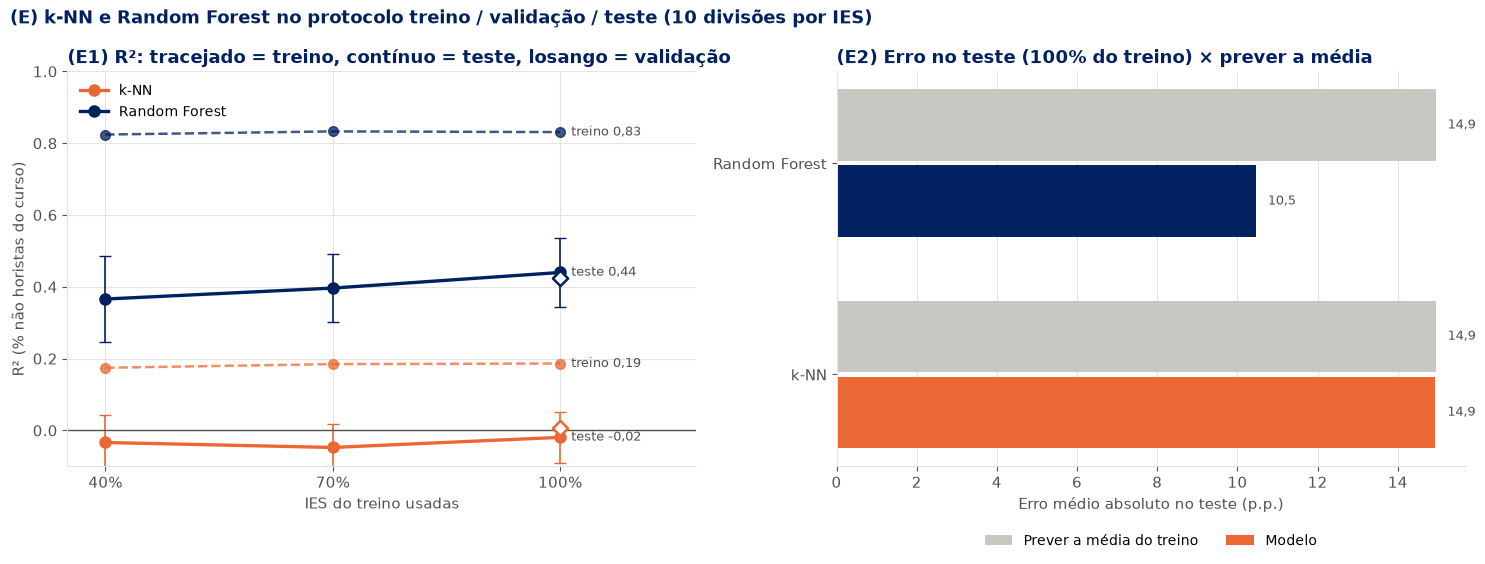

In [7]:
# Célula 7 — Random Forest: o que o perfil de docentes da instituição (Censo) e a área preveem para o % de não horistas do curso
# A área entra como atributo para que a previsão de cada curso da PUC-Rio desconte o nível típico da área no país.
# Mesmo protocolo da célula 4. A validação escolhe o tamanho mínimo da folha e a fração de atributos por divisão.
# Modelo final: o da semente 42 (mesma divisão do modelo final do C2). A PUC-Rio nunca entra no treino.
# Importância: por permutação no TESTE de cada divisão (média das 10). Percentil: entre os erros do teste.

GRADE_RF = [(folha, frac) for folha in [1, 5, 10, 20] for frac in [1.0, 0.33]]
fab_rf = lambda par: RandomForestRegressor(n_estimators=300, min_samples_leaf=par[0], max_features=par[1],
                                           random_state=SEMENTE, n_jobs=-1)
log_rf, mod_rf = avaliar("Random Forest", fab_rf, GRADE_RF, ATRIB_RF)
qualidade = pd.concat([resumir(log_knn), resumir(log_rf)], ignore_index=True)
log_sup = pd.concat([log_knn, log_rf], ignore_index=True)

ATRIB_IES = [c for c in ATRIB_RF if c not in COLS_AREA]
imps, residuos = [], []
for sem, m in mod_rf.items():
    te = DIVISOES[sem][1]; Xte, yte = sup.loc[te, ATRIB_RF], sup.loc[te, ALVO]
    r2_base = r2_score(yte, m.predict(Xte)); ger = np.random.default_rng(sem); linha = {}
    for nome_bloco, cols_b in [(c, [c]) for c in ATRIB_IES] + [("Área do curso (8 indicadoras juntas)", COLS_AREA)]:
        quedas = []
        for _ in range(10):   # permuta o bloco inteiro (a área como um só atributo) e mede a queda do R² no teste
            Xp = Xte.copy(); Xp[cols_b] = Xp[cols_b].to_numpy()[ger.permutation(len(Xp))]
            quedas.append(r2_base - r2_score(yte, m.predict(Xp)))
        linha[nome_bloco] = np.mean(quedas)
    imps.append(linha)
    if sem == SEMENTE:
        residuos = (yte - m.predict(Xte)).to_numpy()
imps = pd.DataFrame(imps)
importancia = imps.mean().sort_values(ascending=False)
importancia_dp = imps.std()[importancia.index]

rf = mod_rf[SEMENTE]
puc_rf = cursos[eh_puc & cursos["Código da Área"].isin(FOCO)].copy()
puc_rf["Curso"] = puc_rf["Código da Área"].map(FOCO)
prev_div = np.column_stack([m.predict(puc_rf[ATRIB_RF]) for m in mod_rf.values()])
puc_rf["Previsto pelo perfil da IES"] = rf.predict(puc_rf[ATRIB_RF])
puc_rf["Diferença (real − previsto)"] = puc_rf[ALVO] - puc_rf["Previsto pelo perfil da IES"]
puc_rf["Diferença mín. (10 divisões)"] = puc_rf[ALVO].to_numpy() - prev_div.max(axis=1)
puc_rf["Diferença máx. (10 divisões)"] = puc_rf[ALVO].to_numpy() - prev_div.min(axis=1)
puc_rf["Percentil da diferença"] = [100 * (residuos < r).mean() for r in puc_rf["Diferença (real − previsto)"]]
puc_rf = puc_rf[["Curso", ALVO, "Previsto pelo perfil da IES", "Diferença (real − previsto)", "Diferença mín. (10 divisões)",
                 "Diferença máx. (10 divisões)", "Percentil da diferença"]].rename(columns={ALVO: "Real (% não horista)"})
q100 = qualidade[qualidade["Proporção"] == 1.0].set_index("Modelo")
rf_r2, rf_mae = q100.loc["Random Forest", "R² teste"], q100.loc["Random Forest", "MAE teste"]
print(f"Random Forest, teste externo (média de 10 divisões): R² = {rf_r2:.3f} | erro médio = {rf_mae:.1f} p.p. | "
      f"parâmetros mais escolhidos: {q100.loc['Random Forest', 'Parâmetros mais escolhidos']}")
display(qualidade.round(3))
display(pd.DataFrame({"Importância (queda no R² do teste)": importancia, "Desvio entre divisões": importancia_dp}).round(3))
display(puc_rf.round(1))

# Gráfico E: R² no treino, na validação e no teste por tamanho do treino; erro no teste × prever a média
CORES_Q = {"k-NN": LARANJA, "Random Forest": AZUL_ESC}
fig, (e1, e2) = plt.subplots(1, 2, figsize=(15, 5.8))
for mdl, cor in CORES_Q.items():
    t = qualidade[qualidade["Modelo"] == mdl].sort_values("Proporção")
    e1.plot(100 * t["Proporção"], t["R² treino"], linestyle="--", marker="o", color=cor, linewidth=1.8, markersize=7, alpha=0.75)
    e1.plot(100 * t["Proporção"], t["R² teste"], marker="o", color=cor, linewidth=2.4, markersize=8, label=f"{mdl}")
    e1.errorbar(100 * t["Proporção"], t["R² teste"], yerr=t["R² teste (desvio)"], fmt="none", ecolor=cor, capsize=4, linewidth=1.2)
    u = t.iloc[-1]
    e1.annotate(f"teste {u['R² teste']:.2f}".replace(".", ","), (100, u["R² teste"]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TXT)
    e1.annotate(f"treino {u['R² treino']:.2f}".replace(".", ","), (100, u["R² treino"]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TXT)
    e1.scatter([100], [u["R² validação"]], marker="D", s=60, color="white", edgecolor=cor, linewidth=1.8, zorder=4)
e1.axhline(0, color=TXT, linewidth=1)
e1.set_xticks([40, 70, 100], ["40%", "70%", "100%"]); e1.set_xlim(35, 118); e1.set_ylim(-0.1, 1.0)
e1.set_xlabel("IES do treino usadas"); e1.set_ylabel("R² (% não horistas do curso)")
e1.set_title("(E1) R²: tracejado = treino, contínuo = teste, losango = validação", loc="left")
e1.legend(loc="upper left", fontsize=10)
t = qualidade[qualidade["Proporção"] == 1.0].set_index("Modelo")
yy = np.arange(len(t))
e2.barh(yy + 0.18, t["MAE teste (média do treino)"], height=0.34, color=CINZA, label="Prever a média do treino")
e2.barh(yy - 0.18, t["MAE teste"], height=0.34, color=[CORES_Q[m] for m in t.index], label="Modelo")
for yi, (b, mm) in enumerate(zip(t["MAE teste (média do treino)"], t["MAE teste"])):
    e2.text(b + 0.3, yi + 0.18, f"{b:.1f}".replace(".", ","), va="center", fontsize=9, color=TXT)
    e2.text(mm + 0.3, yi - 0.18, f"{mm:.1f}".replace(".", ","), va="center", fontsize=9, color=TXT)
e2.set_yticks(yy, t.index); e2.grid(axis="y", visible=False); e2.set_xlabel("Erro médio absoluto no teste (p.p.)")
e2.set_title("(E2) Erro no teste (100% do treino) × prever a média", loc="left")
e2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=10)
fig.suptitle("(E) k-NN e Random Forest no protocolo treino / validação / teste (10 divisões por IES)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=AZUL_ESC)
plt.tight_layout(); fig.savefig(pasta_saida / "E_knn_rf_treino_teste.png", dpi=200, bbox_inches="tight"); plt.show()

## Agrupamento hierárquico (Cabezas, Izbicki e Stern, 2023)

Versão simplificada em Python do método do artigo:
- **CVL:** compara métodos hierárquicos prevendo cada indicador pela árvore montada sem ele (menor é melhor).
  O K-means do C2 entra na mesma régua, mas uma árvore inteira prevê mais que 4 grupos, então a comparação favorece a árvore.
- **Importância dos indicadores:** quanto cada indicador é explicado pela árvore (PFIS) e pelos 4 grupos do C2 (R²).
- **Pares em níveis:** os grupos da PUC-Rio ao subir na árvore (Ward), do mais próximo ao mais amplo.

In [8]:
# Célula 8 — Agrupamento hierárquico (Cabezas, Izbicki e Stern, 2023), versão simplificada em Python
# A árvore é tratada como uma filogenia: cada indicador "evolui" nela por movimento browniano.
#   CVL : perda para escolher o método (prevê cada indicador pela árvore montada sem ele; menor é melhor)
#   PFIS: importância de cada indicador na árvore; comparada ao R² dos 4 grupos do K-means (C2)

METODOS = ["ward", "average", "complete", "weighted", "single"]

def prever_pela_arvore(Z, yv, ruido=1e-3):
    h = squareform(cophenet(Z)); H = Z[:, 2].max()
    Cm = (H - h) / H; np.fill_diagonal(Cm, 1.0); Cm += ruido * np.eye(len(yv))
    Q = np.linalg.inv(Cm); um = np.ones(len(yv))
    mu = (um @ Q @ yv) / (um @ Q @ um); r = yv - mu
    return mu + r - (Q @ r) / np.diag(Q)

def prever_pelo_grupo(g, yv):
    s = pd.Series(yv).groupby(g).transform("sum").to_numpy(); n = pd.Series(g).map(pd.Series(g).value_counts()).to_numpy()
    return np.where(n > 1, (s - yv) / np.maximum(n - 1, 1), yv.mean())

cvl, pfis, niveis, arvores = [], [], [], {}
for a, nome in FOCO.items():
    d = grupos_c2[a]["dados"]; pos = grupos_c2[a]["pos"]
    Xa = StandardScaler().fit_transform(d[IND]); k = int(k_c2[a])
    for m in METODOS + ["K-means C2"]:
        erros = []
        for j in range(len(IND)):
            Xm = np.delete(Xa, j, axis=1)
            pred = (prever_pelo_grupo(KMeans(n_clusters=k, random_state=SEMENTE, n_init=20).fit_predict(Xm), Xa[:, j])
                    if m == "K-means C2" else prever_pela_arvore(linkage(Xm, method=m), Xa[:, j]))
            erros.append(np.mean((Xa[:, j] - pred) ** 2))
        cvl.append({"Curso": nome, "Método": m, "CVL": np.mean(erros)})
    Z = linkage(Xa, method="ward"); arvores[a] = (Z, d, pos)
    g_km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=20).fit_predict(Xa)
    for j, nm in enumerate(NOMES):
        pfis.append({"Curso": nome, "Indicador": nm,
                     "PFIS (Ward)": 1 - np.mean((Xa[:, j] - prever_pela_arvore(Z, Xa[:, j])) ** 2) / Xa[:, j].var(),
                     "R² dos 4 grupos (K-means C2)": 1 - np.mean((Xa[:, j] - prever_pelo_grupo(g_km, Xa[:, j])) ** 2) / Xa[:, j].var()})
    # pares em níveis: sobe a árvore a partir da PUC-Rio
    _, nos = to_tree(Z, rd=True); pai = {}
    for no in nos:
        if not no.is_leaf():
            pai[no.left.id] = no; pai[no.right.id] = no
    pares_c2 = set(np.flatnonzero(grupos_c2[a]["grupos"] == grupos_c2[a]["grupos"][pos])) - {pos}
    no, vistos = nos[pos], set()
    for limiar in [5, 25, 100]:
        while no.count - 1 < limiar and no.id in pai:
            no = pai[no.id]
        if no.id in vistos:
            continue
        vistos.add(no.id); membros = [i for i in no.pre_order() if i != pos]; sub = d.loc[membros]
        niveis.append({"Curso": nome, "Nível": f"≥ {limiar} pares", "Pares": len(membros),
                       "% públicos": 100 * sub["Pública"].mean(), "Regime médio": sub["Regime_Trabalho_2023"].mean(),
                       "ENADE médio": sub["Enade_2023"].mean(), "% também no grupo C2": 100 * len(set(membros) & pares_c2) / len(membros),
                       "Exemplos": ", ".join(sub["Sigla da IES"].fillna("").astype(str).head(6))})
cvl = pd.DataFrame(cvl); pfis = pd.DataFrame(pfis); niveis = pd.DataFrame(niveis)
display(cvl.pivot(index="Método", columns="Curso", values="CVL").round(3))
display(pfis.pivot(index="Indicador", columns="Curso", values="R² dos 4 grupos (K-means C2)").loc[NOMES].round(2))
display(niveis.round(1))

Curso,Arquitetura e Urbanismo,Engenharia Civil,Engenharia de Produção
Método,,,
K-means C2,0.684,0.599,0.690
average,0.584,0.439,0.526
complete,0.615,0.453,0.540
single,0.721,0.660,0.699
ward,0.620,0.462,0.548
weighted,0.576,0.434,0.522


Curso,Arquitetura e Urbanismo,Engenharia Civil,Engenharia de Produção
Indicador,,,
ENADE,0.56,0.63,0.49
IDD,0.41,0.55,0.42
Mestres,0.56,0.45,0.57
Doutores,0.44,0.44,0.43
Regime,0.28,0.33,0.33
Org. didática,0.55,0.59,0.55
Infraestrutura,0.55,0.60,0.56
Oportunidades,0.54,0.55,0.45


,Curso,Nível,Pares,% públicos,Regime médio,ENADE médio,% também no grupo C2,Exemplos
0,Engenharia Civil,≥ 5 pares,10,0.0,2.7,3.0,10.0,"CEUN-IMT, UCS, PUCRS, FEI, UNISC, UNIFOR"
1,Engenharia Civil,≥ 25 pares,46,4.3,2.2,2.5,2.2,"UNISAL, IESB, FTEC Porto Alegre, PUC MINAS, UN..."
2,Engenharia Civil,≥ 100 pares,164,3.0,3.6,2.3,1.2,"UVA, UNIVIÇOSA, UVV, SENAI CIMATEC, , UNIFAMAZ"
3,Engenharia de Produção,≥ 5 pares,9,11.1,2.1,2.8,66.7,"UNESA, UNILASALLE/RJ, UniMetrocamp Wyden, FEI,..."
4,Engenharia de Produção,≥ 25 pares,51,11.8,3.2,2.4,39.2,"ITCSAS/CENSA, FACCAT, UCAM, CEUNSP, UNIFEG, PU..."
5,Engenharia de Produção,≥ 100 pares,108,9.3,3.8,2.5,71.3,"UNIVALI, FHO, , UNIVATES, UNAERP, UniFACENS"
6,Arquitetura e Urbanismo,≥ 5 pares,5,20.0,1.3,2.5,100.0,"FURB, UNICEUB, UNICEUB, CUFSA, URI"
7,Arquitetura e Urbanismo,≥ 25 pares,32,3.1,1.9,2.8,25.0,"FURB, UNICEUB, UNICEUB, CUFSA, URI, FADIC"
8,Arquitetura e Urbanismo,≥ 100 pares,110,0.9,3.2,2.5,38.2,"UNIPAR, FAMETRO, , UNIVATES, UniEVANGÉLICA, UN..."


## Hierárquico com o mesmo protocolo do K-means

Para ficar comparável aos outros métodos do plano de experimento, o hierárquico é refeito com o mesmo protocolo:
divisão treino/teste 80/20 dentro de cada área, 10 divisões (sementes 42 a 51) e 40%, 70% e 100% do treino.

- A árvore (Ward e McQuitty) é montada **só no treino** e cortada no K do C2 (K=4).
- Cada curso de teste vai para o grupo de centro mais próximo, como no K-means.
- Métricas: silhueta no treino e no teste, Davies–Bouldin, estabilidade entre divisões (ARI), estabilidade dos pares da PUC-Rio (Jaccard)
  e ganho sobre dados sem grupos. A CVL do artigo é calculada só no treino.
- O K-means do C2 entra na mesma tabela, com os números do notebook 09.

Depois de validar, os pares em níveis e o dendrograma usam todos os cursos da área, como o modelo final do C2.

Silhueta teste  Ganho    ARI  \
Curso                   Método                                       
Engenharia Civil        Ward                   0.248  0.064  0.714   
                        McQuitty               0.189  0.023  0.316   
Engenharia de Produção  Ward                   0.220  0.055  0.727   
                        McQuitty               0.187  0.019  0.361   
Arquitetura e Urbanismo Ward                   0.216  0.035  0.612   
                        McQuitty               0.162  0.012  0.311   
Engenharia Civil        K-means (C2)           0.258  0.066  0.948   
Engenharia de Produção  K-means (C2)           0.219  0.053  0.825   
Arquitetura e Urbanismo K-means (C2)           0.232  0.053  0.942   

                                      Jaccard PUC  DB teste  Menor grupo  \
Curso                   Método                                             
Engenharia Civil        Ward                0.902     1.281         28.0   
                        McQuitty            0.314     1.431          1.0   
Engenharia de Produção  Ward                0.488     1.292         18.0   
                        McQuitty            0.570     1.309          1.0   
Arquitetura e Urbanismo Ward                0.530     1.396         15.0   
                        McQuitty            0.404     1.403          1.0   
Engenharia Civil        K-means (C2)        0.967     1.236          NaN   
Engenharia de Produção  K-means (C2)        0.852     1.288          NaN   
Arquitetura e Urbanismo K-means (C2)        0.937     1.335          NaN   

                                      CVL treino  
Curso                   Método                    
Engenharia Civil        Ward               0.466  
                        McQuitty           0.445  
Engenharia de Produção  Ward               0.578  
                        McQuitty           0.551  
Arquitetura e Urbanismo Ward               0.623  
                        McQuitty           0.585  
Engenharia Civil        K-means (C2)         NaN  
Engenharia de Produção  K-means (C2)         NaN  
Arquitetura e Urbanismo K-means (C2)         NaN

Proporção                               0.4    0.7    1.0
Curso                   Método                           
Engenharia Civil        Ward          0.593  0.634  0.714
                        McQuitty      0.441  0.425  0.316
                        K-means (C2)  0.760  0.896  0.948
Engenharia de Produção  Ward          0.590  0.723  0.727
                        McQuitty      0.410  0.379  0.361
                        K-means (C2)  0.706  0.743  0.825
Arquitetura e Urbanismo Ward          0.520  0.521  0.612
                        McQuitty      0.348  0.312  0.311
                        K-means (C2)  0.651  0.845  0.942

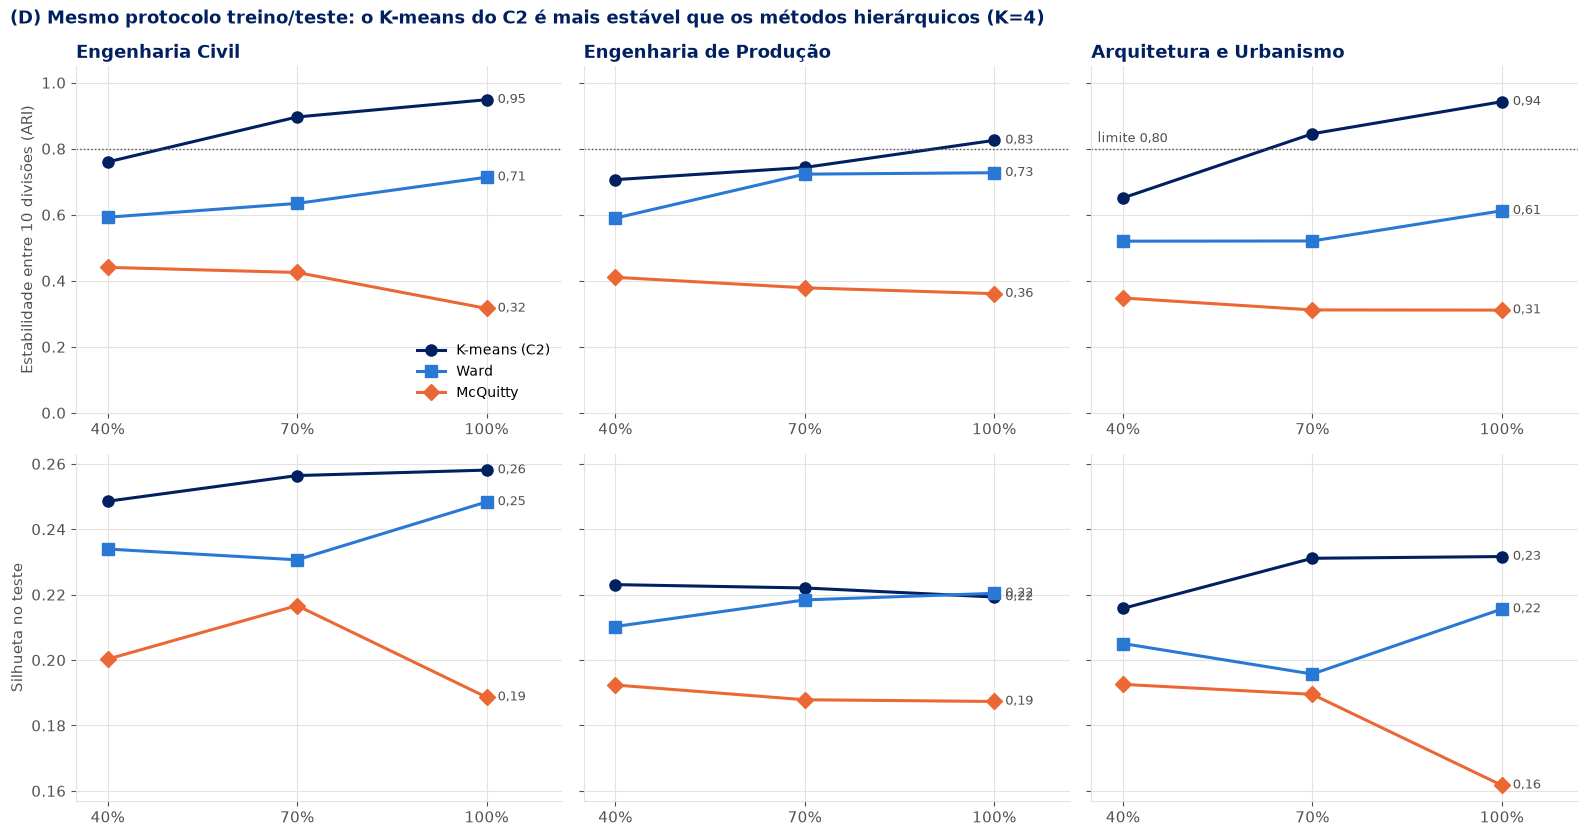

In [9]:
# Célula 9 — Hierárquico com o mesmo protocolo do K-means: treino/teste 80/20, 10 divisões, 40/70/100% do treino
# A árvore é montada só no treino e cortada no K do C2; cada curso de teste (e cada curso da área) vai para o grupo
# de centro mais próximo. A CVL do artigo é calculada só no treino. O K-means do C2 vem do notebook 09 (mesmo protocolo).
import itertools
from scipy.stats import norm, rankdata
from sklearn.metrics import davies_bouldin_score, pairwise_distances, silhouette_score

SEMENTES, PROPORCOES, METODOS_TT = list(range(42, 52)), [0.4, 0.7, 1.0], ["ward", "weighted"]

def referencia_copula(Xs, sem):
    ger = np.random.default_rng(sem); n, p = Xs.shape
    esc = np.column_stack([norm.ppf((rankdata(Xs[:, j]) - 0.5) / n) for j in range(p)])
    u = norm.cdf(ger.multivariate_normal(np.zeros(p), np.corrcoef(esc, rowvar=False), size=n))
    return np.column_stack([np.quantile(Xs[:, j], u[:, j]) for j in range(p)])

def medir(Xs, r):
    return (silhouette_score(Xs, r), davies_bouldin_score(Xs, r)) if len(np.unique(r)) > 1 else (np.nan, np.nan)

def cortar(Xs, metodo, k):
    r = fcluster(linkage(Xs, method=metodo), t=k, criterion="maxclust") - 1
    return r, np.array([Xs[r == g].mean(axis=0) for g in range(r.max() + 1)])

linhas_tt, rot_tt = [], {}
for a, nome in FOCO.items():
    d = grupos_c2[a]["dados"]; pos = grupos_c2[a]["pos"]; k = int(k_c2[a])
    for sem in SEMENTES:
        tr, te = train_test_split(np.arange(len(d)), test_size=0.2, random_state=sem)
        ordem = np.random.default_rng(sem).permutation(tr)
        for prop in PROPORCOES:
            sub = ordem[:int(round(prop * len(ordem)))]
            esc = StandardScaler().fit(d.loc[sub, IND])
            Xs, Xt, Xall = (esc.transform(d.loc[i, IND]) for i in (sub, te, np.arange(len(d))))
            for metodo in METODOS_TT:
                r_tr, centros = cortar(Xs, metodo, k)
                r_te = pairwise_distances(Xt, centros).argmin(axis=1)
                r_all = pairwise_distances(Xall, centros).argmin(axis=1)
                sil_tr, db_tr = medir(Xs, r_tr); sil_te, db_te = medir(Xt, r_te)
                lin = {"Curso": nome, "Método": metodo, "Proporção": prop, "Semente": sem, "K": k, "N treino": len(sub),
                       "N teste": len(te), "Inércia": float(((Xs - centros[r_tr]) ** 2).sum()),
                       "Silhueta treino": sil_tr, "Silhueta teste": sil_te, "DB treino": db_tr, "DB teste": db_te,
                       "Menor grupo": int(np.bincount(r_tr).min())}
                if prop == 1.0:
                    Xn = referencia_copula(Xs, sem + 1000)
                    lin["Silhueta nula"] = medir(Xn, cortar(Xn, metodo, k)[0])[0]
                    erros = [np.mean((Xs[:, j] - prever_pela_arvore(linkage(np.delete(Xs, j, axis=1), method=metodo), Xs[:, j])) ** 2)
                             for j in range(len(IND))]
                    lin["CVL treino"] = np.mean(erros)
                linhas_tt.append(lin)
                rot_tt.setdefault((nome, metodo, prop), {})[sem] = r_all

est = []
for (nome, metodo, prop), reps in rot_tt.items():
    pos = grupos_c2[[a for a in FOCO if FOCO[a] == nome][0]]["pos"]; aris, jacs = [], []
    for s1, s2 in itertools.combinations(sorted(reps), 2):
        r1, r2 = reps[s1], reps[s2]; aris.append(adjusted_rand_score(r1, r2))
        p1 = set(np.flatnonzero(r1 == r1[pos])) - {pos}; p2 = set(np.flatnonzero(r2 == r2[pos])) - {pos}
        jacs.append(len(p1 & p2) / len(p1 | p2) if p1 | p2 else 1.0)
    est.append({"Curso": nome, "Método": metodo, "Proporção": prop, "ARI": np.mean(aris), "Jaccard PUC": np.mean(jacs)})
hier_tt = (pd.DataFrame(linhas_tt).groupby(["Curso", "Método", "Proporção"], sort=False)
           .agg(**{c: (c, "mean") for c in ["K", "N treino", "N teste", "Inércia", "Silhueta treino", "Silhueta teste",
                                             "Silhueta nula", "DB treino", "DB teste", "CVL treino"]},
                **{"Menor grupo": ("Menor grupo", "min")})
           .reset_index().merge(pd.DataFrame(est), on=["Curso", "Método", "Proporção"]))
hier_tt["Ganho"] = hier_tt["Silhueta treino"] - hier_tt["Silhueta nula"]

# K-means do C2 no mesmo protocolo (notebook 09), para comparar na mesma régua
r09 = pd.read_csv("resultados_notebook_09/resumo_por_configuracao.csv", sep=";", decimal=",")
log09 = pd.read_csv("resultados_notebook_09/log_execucoes.csv", sep=";", decimal=",")
db_tr09 = log09.groupby(["Area", "Cenario", "Escalonador", "Algoritmo", "Proporcao", "K"])["DB_treino"].mean()
km = []
for a, nome in FOCO.items():
    for prop in PROPORCOES:
        f = r09[(r09["Area"] == a) & (r09["Cenario"] == "C2_8IND") & (r09["Escalonador"] == "Standard")
                & (r09["Algoritmo"] == "K-means") & (r09["Proporcao"] == prop) & (r09["K"] == int(k_c2[a]))].iloc[0]
        km.append({"Curso": nome, "Método": "K-means (C2)", "Proporção": prop, "K": int(k_c2[a]), "N treino": f["N_treino"],
                   "Inércia": f["Inercia"], "Silhueta treino": f["Silhueta_treino"], "Silhueta teste": f["Silhueta_teste"],
                   "Silhueta nula": f["Silhueta_nula"], "DB treino": db_tr09.get((a, "C2_8IND", "Standard", "K-means", prop, int(k_c2[a]))),
                   "DB teste": f["DB_teste"], "ARI": f["ARI_medio"], "Jaccard PUC": f["Jaccard_PUC"],
                   "Ganho": f["Silhueta_treino"] - f["Silhueta_nula"] if pd.notna(f["Silhueta_nula"]) else np.nan})
hier_tt = pd.concat([hier_tt, pd.DataFrame(km)], ignore_index=True)
hier_tt["Método"] = hier_tt["Método"].replace({"ward": "Ward", "weighted": "McQuitty"})
cols = ["Silhueta teste", "Ganho", "ARI", "Jaccard PUC", "DB teste", "Menor grupo", "CVL treino"]
display(hier_tt[hier_tt["Proporção"] == 1.0].set_index(["Curso", "Método"])[cols].round(3))
display(hier_tt.pivot_table(index=["Curso", "Método"], columns="Proporção", values="ARI", sort=False).round(3))

# Gráfico D: estabilidade (ARI) e silhueta no teste por tamanho do treino, K-means × Ward × McQuitty
CORES_M = {"K-means (C2)": AZUL_ESC, "Ward": AZUL, "McQuitty": LARANJA}
MARC_M = {"K-means (C2)": "o", "Ward": "s", "McQuitty": "D"}
fig, eixos = plt.subplots(2, 3, figsize=(16, 8.5), sharey="row")
for j, nome in enumerate(FOCO.values()):
    for i, (col, rot) in enumerate([("ARI", "Estabilidade entre 10 divisões (ARI)"), ("Silhueta teste", "Silhueta no teste")]):
        ax = eixos[i, j]
        for m in CORES_M:
            t = hier_tt[(hier_tt["Curso"] == nome) & (hier_tt["Método"] == m)].sort_values("Proporção")
            ax.plot(100 * t["Proporção"], t[col], marker=MARC_M[m], linewidth=2.2, markersize=8, color=CORES_M[m], label=m)
            ultimo = t.iloc[-1]
            ax.annotate(f"{ultimo[col]:.2f}".replace(".", ","), (100, ultimo[col]), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=9, color=TXT)
        if col == "ARI":
            ax.axhline(0.80, color=TXT, linestyle=":", linewidth=1)
            ax.set_ylim(0, 1.05); ax.set_title(nome, loc="left")
        ax.set_xticks([40, 70, 100], ["40%", "70%", "100%"]); ax.set_xlim(35, 112)
        if j == 0:
            ax.set_ylabel(rot)
eixos[0, 0].legend(loc="lower right", fontsize=10)
eixos[0, 2].text(36, 0.82, "limite 0,80", fontsize=9, color=TXT)
fig.suptitle("(D) Mesmo protocolo treino/teste: o K-means do C2 é mais estável que os métodos hierárquicos (K=4)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=AZUL_ESC)
plt.tight_layout(); fig.savefig(pasta_saida / "D_hierarquico_treino_teste.png", dpi=200, bbox_inches="tight"); plt.show()

## Gráficos

- **(A)** Composição do regime dos docentes (Censo) da PUC-Rio e das instituições de referência.
- **(B)** Para cada curso da PUC-Rio, o percentual real de não horistas menos o previsto pelo perfil da instituição.
- **(C)** Dendrograma de cada curso colorido pelo Regime; em laranja, o caminho da PUC-Rio até a raiz.

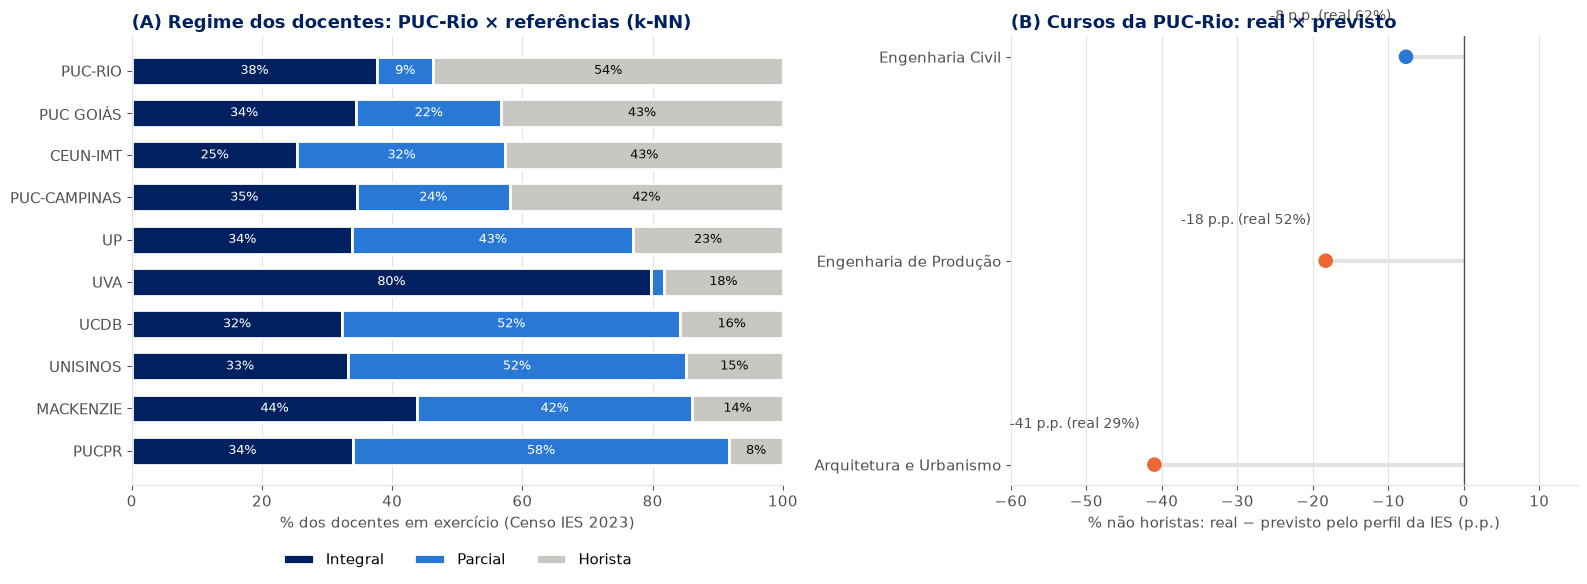

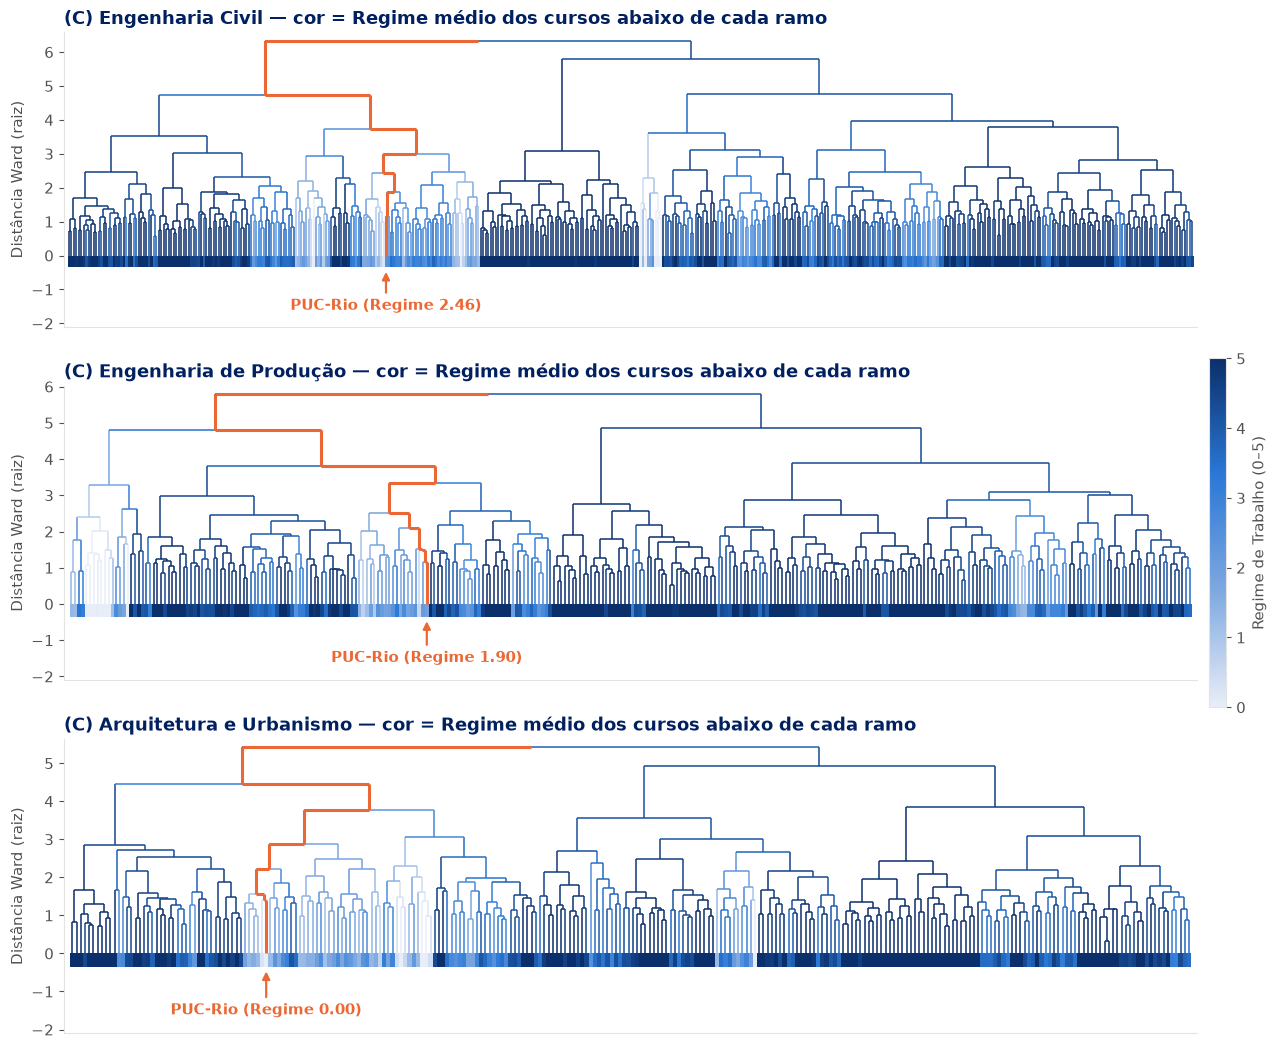

In [10]:
# Célula 10 — Gráficos: (A) regime dos docentes da PUC-Rio × referências; (B) real × previsto; (C) dendrograma pelo Regime

siglas = ["PUC-RIO"] + referencias["Sigla"].value_counts().index[:9].tolist()
t = ies[ies["SG_IES"].isin(siglas)].drop_duplicates("SG_IES").set_index("SG_IES").loc[siglas]
comp = t[["IES % integral", "IES % parcial", "IES % horista"]].sort_values("IES % horista")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.15, 1]})
esq = np.zeros(len(comp))
for col, cor in [("IES % integral", AZUL_ESC), ("IES % parcial", AZUL), ("IES % horista", CINZA)]:
    a1.barh(range(len(comp)), comp[col], left=esq, color=cor, label=col.replace("IES % ", "").capitalize(), height=0.66, edgecolor="white", linewidth=2)
    for yi, (l, vv) in enumerate(zip(esq, comp[col])):
        if vv >= 7:
            a1.text(l + vv / 2, yi, f"{vv:.0f}%", ha="center", va="center", fontsize=9, color="white" if col != "IES % horista" else "#0b0b0b")
    esq += comp[col].to_numpy()
a1.set_yticks(range(len(comp)), comp.index); a1.set_xlim(0, 100); a1.grid(axis="y", visible=False)
a1.set_xlabel("% dos docentes em exercício (Censo IES 2023)"); a1.set_title("(A) Regime dos docentes: PUC-Rio × referências (k-NN)", loc="left")
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
r = puc_rf.sort_values("Diferença (real − previsto)")
a2.hlines(range(len(r)), 0, r["Diferença (real − previsto)"], color=GRADE, linewidth=3)
a2.scatter(r["Diferença (real − previsto)"], range(len(r)), color=[LARANJA if x < -10 else AZUL for x in r["Diferença (real − previsto)"]], s=90, zorder=3)
for yi, (dv, real) in enumerate(zip(r["Diferença (real − previsto)"], r["Real (% não horista)"])):
    a2.text(dv - 2, yi + 0.18, f"{dv:+.0f} p.p. (real {real:.0f}%)", ha="right", fontsize=10, color=TXT)
a2.axvline(0, color=TXT, linewidth=1); a2.set_yticks(range(len(r)), r["Curso"]); a2.set_xlim(-60, 15); a2.grid(axis="y", visible=False)
a2.set_xlabel("% não horistas: real − previsto pelo perfil da IES (p.p.)"); a2.set_title("(B) Cursos da PUC-Rio: real × previsto", loc="left")
plt.tight_layout(); fig.savefig(pasta_saida / "A_B_regime_censo_e_residuo.png", dpi=200, bbox_inches="tight"); plt.show()

cmap = LinearSegmentedColormap.from_list("regime", ["#e8eef8", "#7fa8e0", "#2a78d6", "#0b2f6b"]); norma = Normalize(0, 5)
fig, eixos = plt.subplots(3, 1, figsize=(15, 13))
for ax, (a, (Z, d, pos)) in zip(eixos, arvores.items()):
    n = len(d); reg = d["Regime_Trabalho_2023"].to_numpy(); folhas = dendrogram(Z, no_plot=True)["leaves"]
    x = np.zeros(2 * n - 1); h = np.zeros(2 * n - 1); soma = np.zeros(2 * n - 1); cont = np.zeros(2 * n - 1)
    x[folhas] = np.arange(n); soma[:n] = reg; cont[:n] = 1; alt = np.sqrt(Z[:, 2]); segs, cores = [], []
    for kk, (c1, c2, _, _) in enumerate(Z):
        c1, c2, no = int(c1), int(c2), n + kk
        x[no] = (x[c1] + x[c2]) / 2; h[no] = alt[kk]; soma[no] = soma[c1] + soma[c2]; cont[no] = cont[c1] + cont[c2]
        for c in (c1, c2):
            segs.append([(x[c], h[c]), (x[c], h[no])]); cores.append(cmap(norma(soma[c] / cont[c])))
        segs.append([(x[c1], h[no]), (x[c2], h[no])]); cores.append(cmap(norma(soma[no] / cont[no])))
    ax.add_collection(LineCollection(segs, colors=cores, linewidths=1.1))
    ax.bar(np.arange(n), -0.35, width=1.0, color=cmap(norma(reg[folhas])))
    filhos = {n + kk: (int(c1), int(c2)) for kk, (c1, c2, _, _) in enumerate(Z)}; pai = {c: p for p, cs in filhos.items() for c in cs}
    no, cam = pos, []
    while no in pai:
        p = pai[no]; cam += [[(x[no], h[no]), (x[no], h[p])], [(x[no], h[p]), (x[p], h[p])]]; no = p
    ax.add_collection(LineCollection(cam, colors=LARANJA, linewidths=2.2))
    ax.annotate(f"PUC-Rio (Regime {reg[pos]:.2f})", xy=(x[pos], -0.4), xytext=(x[pos], -1.6), ha="center", fontweight="bold",
                color=LARANJA, arrowprops={"arrowstyle": "-|>", "color": LARANJA, "lw": 1.6})
    ax.set_xlim(-2, n + 1); ax.set_ylim(-2.1, alt.max() * 1.04); ax.set_xticks([]); ax.grid(False)
    ax.set_ylabel("Distância Ward (raiz)"); ax.set_title(f"(C) {FOCO[a]} — cor = Regime médio dos cursos abaixo de cada ramo", loc="left")
fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=cmap), ax=eixos, fraction=0.015, pad=0.01).set_label("Regime de Trabalho (0–5)")
fig.savefig(pasta_saida / "C_dendrograma_regime_3cursos.png", dpi=170, bbox_inches="tight"); plt.show()

## Registro

As tabelas vão para `resultados_notebook_11/`. No MLflow, um run geral (qualidade do k-NN e do Random Forest
em treino, validação e teste, e decomposição de variância) e um run por curso (referências e sua estabilidade,
real × previsto, métodos hierárquicos e importância dos indicadores).

In [11]:
# Célula 11 — Tabelas e registro no MLflow (um run geral + um run por curso)

opc = {"sep": ";", "decimal": ",", "index": False, "encoding": "utf-8-sig"}
tabelas = {"perfil_puc_vs_pares_censo.csv": perfil, "referencias_knn.csv": referencias, "decomposicao_variancia.csv": icc,
           "rf_importancia.csv": importancia.rename("Importância").reset_index().rename(columns={"index": "Atributo"}),
           "rf_puc_real_vs_previsto.csv": puc_rf, "hier_cvl.csv": cvl, "hier_pfis.csv": pfis, "hier_pares_em_niveis.csv": niveis,
           "hier_treino_teste.csv": hier_tt, "knn_rf_qualidade.csv": qualidade, "knn_rf_log_divisoes.csv": log_sup}
for nome_arq, tab in tabelas.items():
    tab.to_csv(pasta_saida / nome_arq, **opc)

import re, unicodedata
def slug(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9]+", "_", s.replace("IES %", "ies_pct")).strip("_").lower()

mlflow.set_tracking_uri("sqlite:///" + Path("mlflow_cpc.db").resolve().as_posix())
if mlflow.get_experiment_by_name(EXPERIMENTO_MLFLOW) is None:
    mlflow.create_experiment(EXPERIMENTO_MLFLOW, artifact_location=Path("mlartifacts").resolve().as_uri())
mlflow.set_experiment(EXPERIMENTO_MLFLOW)
execucao = time.strftime("%Y-%m-%d %H:%M")

with mlflow.start_run(run_name="Geral · k-NN, Random Forest e decomposição de variância", tags={"execucao": execucao, "nivel": "geral"}):
    mlflow.log_params({"protocolo": "teste externo 20% por IES; GroupKFold(5) no treino; sementes 42-51; 40/70/100% das IES do treino",
                       "rf_n_estimators": 300, "rf_grade": str(GRADE_RF), "knn_grade": str(GRADE_KNN),
                       "rf_param_escolhido": q100.loc["Random Forest", "Parâmetros mais escolhidos"],
                       "knn_param_escolhido": q100.loc["k-NN", "Parâmetros mais escolhidos"], "knn_distancia_referencias": METRICA_REF,
                       "cursos_supervisionado": len(sup), "ies_supervisionado": int(sup["Código da IES"].nunique()),
                       "icc_metodo": "ANOVA 1 fator (IES), descontada a área", "fonte_censo": "MICRODADOS_ED_SUP_IES_2023"})
    mlflow.log_metrics({"efeito_ies_puc_pp": efeito_puc,
                        **{f"{slug(m)}_{slug(c)}_{int(100 * p)}": float(r[c]) for _, r in qualidade.iterrows()
                           for m, p in [(r["Modelo"], r["Proporção"])]
                           for c in ["R² treino", "R² validação", "R² teste", "MAE treino", "MAE validação", "MAE teste",
                                     "MAE teste (média do treino)", "Ganho sobre a média (p.p.)"] if pd.notna(r[c])},
                        **{f"icc_{slug(r['Recorte'])}": r["% da variação que vem da IES"] / 100 for _, r in icc.iterrows()},
                        **{f"rf_imp_{slug(k)}": float(vv) for k, vv in importancia.items()}})
    mlflow.log_artifact(str(pasta_saida / "A_B_regime_censo_e_residuo.png"), artifact_path="graficos")
    mlflow.log_artifact(str(pasta_saida / "E_knn_rf_treino_teste.png"), artifact_path="graficos")
    for nome_arq in ["decomposicao_variancia.csv", "rf_importancia.csv", "rf_puc_real_vs_previsto.csv", "perfil_puc_vs_pares_censo.csv",
                     "knn_rf_qualidade.csv", "knn_rf_log_divisoes.csv"]:
        mlflow.log_artifact(str(pasta_saida / nome_arq), artifact_path="tabelas")

for a, nome in FOCO.items():
    with mlflow.start_run(run_name=f"{a} · {nome}", tags={"execucao": execucao, "nivel": "curso"}):
        linha_rf = puc_rf[puc_rf["Curso"] == nome].iloc[0]
        cv_a = cvl[cvl["Curso"] == nome].set_index("Método")["CVL"]
        pf_a = pfis[pfis["Curso"] == nome].set_index("Indicador")
        mlflow.log_params({"area_codigo": a, "curso": nome, "k_c2": int(k_c2[a]), "knn_vizinhos": 5, "knn_distancia": METRICA_REF,
                           "knn_atributos": ", ".join(ATRIB_KNN), "hier_metodo_dendrograma": "ward",
                           "referencias_knn": ", ".join(referencias.loc[referencias["Curso"] == nome, "Sigla"].astype(str))})
        mlflow.log_metrics({"pct_nao_horista_real": linha_rf["Real (% não horista)"],
                            "pct_nao_horista_previsto_rf": linha_rf["Previsto pelo perfil da IES"],
                            "diferenca_real_previsto_pp": linha_rf["Diferença (real − previsto)"],
                            "diferenca_min_10_divisoes_pp": linha_rf["Diferença mín. (10 divisões)"],
                            "diferenca_max_10_divisoes_pp": linha_rf["Diferença máx. (10 divisões)"],
                            "knn_estabilidade_referencias_pct": float(estab_ref[nome]),
                            **{f"cvl_{slug(m)}": float(vv) for m, vv in cv_a.items()},
                            **{f"r2_grupos_{slug(i)}": float(vv) for i, vv in pf_a["R² dos 4 grupos (K-means C2)"].items()},
                            **{f"pfis_{slug(i)}": float(vv) for i, vv in pf_a["PFIS (Ward)"].items()}})
        tt = hier_tt[(hier_tt["Curso"] == nome) & (hier_tt["Proporção"] == 1.0)].set_index("Método")
        mlflow.log_metrics({f"tt_{slug(m)}_{slug(c)}": float(tt.loc[m, c]) for m in tt.index
                            for c in ["Silhueta teste", "Ganho", "ARI", "Jaccard PUC", "DB teste"] if pd.notna(tt.loc[m, c])})
        mlflow.log_artifact(str(pasta_saida / "C_dendrograma_regime_3cursos.png"), artifact_path="graficos")
        mlflow.log_artifact(str(pasta_saida / "D_hierarquico_treino_teste.png"), artifact_path="graficos")
        for nome_arq in ["referencias_knn.csv", "hier_cvl.csv", "hier_pfis.csv", "hier_pares_em_niveis.csv", "hier_treino_teste.csv"]:
            mlflow.log_artifact(str(pasta_saida / nome_arq), artifact_path="tabelas")

print("Experimento:", EXPERIMENTO_MLFLOW, "| runs: 1 geral + 3 cursos")
print('Interface: python -m mlflow ui --backend-store-uri "sqlite:///mlflow_cpc.db" --port 5000 --workers 1')

Experimento: CPC2023_referencias_e_regime_3cursos | runs: 1 geral + 3 cursos
Interface: python -m mlflow ui --backend-store-uri "sqlite:///mlflow_cpc.db" --port 5000 --workers 1
